# Phase 2 — MovieLens Data Preprocessing & Per-User Temporal Splitting

## Objectives
- Validate MovieLens Latest Small and maintain stable user/movie/genre mappings.
- Label positive interactions (rating >= 4.0).
- Use **per_user_temporal** splitting (target 80/10/10), keeping equal timestamps together within each user.
- Verify interaction coverage, per-user chronological order and warm-start evaluation eligibility.
- Save processed datasets, split metadata and reproducible Phase 2 results.

**Primary protocol:** Per-User Temporal Split. **Secondary protocol:** Global Temporal Split (archived under `experiments/global_temporal/`).

**Execution environment:** Windows 11, VS Code, local Python `.venv`.

**Scope:** Phase 2 only; graphs and baseline checkpoints must be rebuilt after changing the split.

Import và cấu hình đường dẫn

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_project_root():
    current = Path.cwd().resolve()

    for candidate in [current, *current.parents]:
        if (candidate / "src" / "data").is_dir():
            return candidate

    raise FileNotFoundError(
        "Cannot find project root. Open the repository in VS Code."
    )

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "ml-latest-small"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"

print("Python:", sys.executable)
print("Project:", PROJECT_ROOT)
print("Dataset exists:", RAW_DIR.exists())

Python: e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Scripts\python.exe
Project: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender
Dataset exists: True


Kiểm tra dữ liệu gốc

In [2]:
ratings_path = RAW_DIR / "ratings.csv"
movies_path = RAW_DIR / "movies.csv"

assert ratings_path.exists(), "Missing ratings.csv"
assert movies_path.exists(), "Missing movies.csv"

ratings = pd.read_csv(ratings_path)
movies = pd.read_csv(movies_path)

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)

display(ratings.head())
display(movies.head())

Ratings shape: (100836, 4)
Movies shape: (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Chạy hoặc xác nhận pipeline Phase 2 (Per-User Temporal). Cell dưới đây **chỉ đọc metadata**, không ghi đè các file đã được tạo bằng PowerShell. Nếu cần tái tạo dữ liệu, chạy `python scripts/prepare_movielens.py --raw-dir data/raw/ml-latest-small --output-root data --split-method per_user_temporal` trong terminal.

In [3]:
with open(SPLITS_DIR / "split_metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

assert metadata["split_method"] == "per_user_temporal", (
    f"Expected per_user_temporal, got {metadata['split_method']}"
)
print("Phase 2 outputs verified; no preprocessing files were overwritten.")
display(pd.DataFrame(metadata.items(), columns=["Metric", "Value"]))

Phase 2 outputs verified; no preprocessing files were overwritten.


,Metric,Value
0,dataset,MovieLens Latest Small
1,split_method,per_user_temporal
2,timestamp_tie_policy,keep_together
3,train_ratio_target,0.8
4,val_ratio_target,0.1
5,test_ratio_target,0.1
6,positive_threshold,4.0
7,seed,42
8,num_users,610
9,num_movies,9742


Đọc dữ liệu sau xử lý

In [4]:
interactions = pd.read_csv(
    PROCESSED_DIR / "interactions.csv"
)

train = pd.read_csv(SPLITS_DIR / "train.csv")
val = pd.read_csv(SPLITS_DIR / "val.csv")
test = pd.read_csv(SPLITS_DIR / "test.csv")

print("Total interactions:", len(interactions))
print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

display(interactions.head(10))

Total interactions: 100836
Train: 80504
Validation: 10149
Test: 10183


,interaction_id,userId,movieId,rating,timestamp,user_idx,movie_idx,is_positive
0,0,429,22,4.0,828124615,428,21,1
1,1,429,150,5.0,828124615,428,123,1
2,2,429,161,5.0,828124615,428,134,1
3,3,429,165,4.0,828124615,428,138,1
4,4,429,218,4.0,828124615,428,186,1
5,5,429,222,4.0,828124615,428,189,1
6,6,429,225,4.0,828124615,428,192,1
7,7,429,227,3.0,828124615,428,193,0
8,8,429,343,3.0,828124615,428,301,0
9,9,429,349,3.0,828124615,428,307,0


Thống kê phân chia dữ liệu

In [5]:
split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Interactions": [
        len(train), len(val), len(test)
    ],
    "Positive": [
        int(train["is_positive"].sum()),
        int(val["is_positive"].sum()),
        int(test["is_positive"].sum())
    ]
})

split_summary["Ratio (%)"] = (
    split_summary["Interactions"]
    / len(interactions) * 100
)

split_summary["Positive Ratio (%)"] = (
    split_summary["Positive"]
    / split_summary["Interactions"] * 100
)

display(split_summary.round(2))

,Split,Interactions,Positive,Ratio (%),Positive Ratio (%)
0,Train,80504,39119,79.84,48.59
1,Validation,10149,4630,10.06,45.62
2,Test,10183,4831,10.10,47.44


Biểu đồ phân bố tương tác theo Per-User Temporal Split

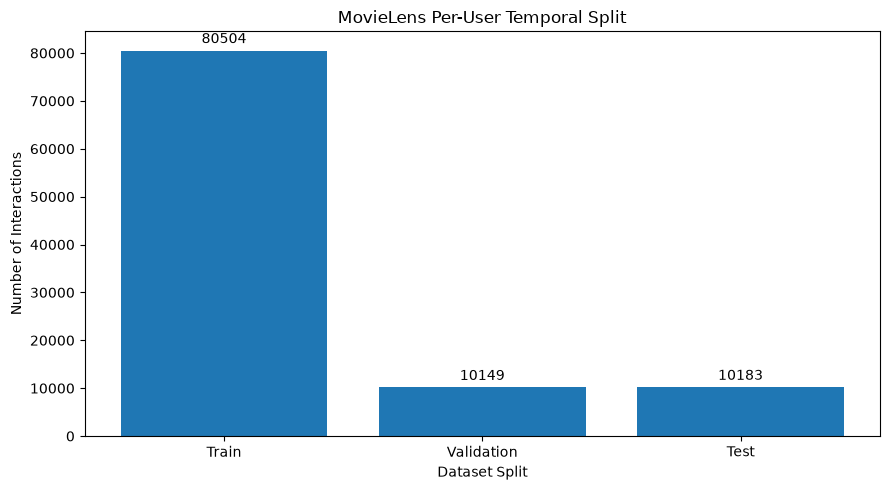

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(split_summary["Split"], split_summary["Interactions"])
ax.bar_label(bars, padding=3)
ax.set_title("MovieLens Per-User Temporal Split")
ax.set_ylabel("Number of Interactions")
ax.set_xlabel("Dataset Split")
plt.tight_layout()
plt.show()

Kiểm tra tính toàn vẹn và thứ tự thời gian **theo từng user** (không yêu cầu Train/Val/Test tách biệt theo timestamp toàn cục)

In [7]:
from src.data.preprocessing import validate_splits

validate_splits(
    train, val, test, interactions,
    split_method="per_user_temporal",
)

all_ids = pd.concat([
    train["interaction_id"], val["interaction_id"], test["interaction_id"]
])
assert all_ids.is_unique
assert len(all_ids) == len(interactions)
assert set(all_ids) == set(interactions["interaction_id"])

# Verify strict ordering and no timestamp ties across splits for each user.
train_bounds = train.groupby("user_idx")["timestamp"].agg(["min", "max"])
val_bounds = val.groupby("user_idx")["timestamp"].agg(["min", "max"])
test_bounds = test.groupby("user_idx")["timestamp"].agg(["min", "max"])

for user in val_bounds.index:
    assert user in train_bounds.index
    assert train_bounds.loc[user, "max"] < val_bounds.loc[user, "min"]
for user in test_bounds.index:
    assert user in val_bounds.index
    assert val_bounds.loc[user, "max"] < test_bounds.loc[user, "min"]

print("Interaction coverage and uniqueness: PASSED")
print("Per-user temporal ordering / timestamp ties: PASSED")

Interaction coverage and uniqueness: PASSED
Per-user temporal ordering / timestamp ties: PASSED


Kiểm tra User/Movie/Genre Mapping

In [8]:
user_mapping = pd.read_csv(
    PROCESSED_DIR / "user_mapping.csv"
)

movie_mapping = pd.read_csv(
    PROCESSED_DIR / "movie_mapping.csv"
)

genre_mapping = pd.read_csv(
    PROCESSED_DIR / "genre_mapping.csv"
)

movie_genres = pd.read_csv(
    PROCESSED_DIR / "movie_genres.csv"
)

mapping_summary = pd.DataFrame({
    "Entity": ["User", "Movie", "Genre", "Movie-Genre Edges"],
    "Count": [
        len(user_mapping),
        len(movie_mapping),
        len(genre_mapping),
        len(movie_genres)
    ]
})

display(mapping_summary)

assert user_mapping["user_idx"].is_unique
assert movie_mapping["movie_idx"].is_unique
assert genre_mapping["genre_idx"].is_unique

assert interactions["user_idx"].isin(
    user_mapping["user_idx"]
).all()

assert interactions["movie_idx"].isin(
    movie_mapping["movie_idx"]
).all()

print("Mapping integrity: PASSED")

,Entity,Count
0,User,610
1,Movie,9742
2,Genre,19
3,Movie-Genre Edges,22050


Mapping integrity: PASSED


Kiểm tra Evaluation Users

In [9]:
evaluation_users = pd.read_csv(
    SPLITS_DIR / "evaluation_users.csv"
)

evaluation_summary = pd.DataFrame({
    "Metric": [
        "Total Users",
        "Eligible Validation Users",
        "Eligible Test Users"
    ],
    "Count": [
        len(evaluation_users),
        int(evaluation_users["eligible_val"].sum()),
        int(evaluation_users["eligible_test"].sum())
    ]
})

display(evaluation_summary)

assert evaluation_users["user_idx"].is_unique

print("Evaluation user eligibility: PASSED")

,Metric,Count
0,Total Users,610
1,Eligible Validation Users,564
2,Eligible Test Users,565


Evaluation user eligibility: PASSED


Chạy toàn bộ Unit Tests liên quan Phase 2

In [10]:
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests",
     "-p", "test_*.py", "-v"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
)
print(result.stdout)
print(result.stderr)
assert result.returncode == 0, "Unit tests failed"
print("All discovered tests: PASSED")


e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
test_bpr_loss (test_baselines.TestBaselines.test_bpr_loss) ... ok
test_full_ranking_filters_history (test_baselines.TestBaselines.test_full_ranking_filters_history) ... ok
test_lightgcn_output_shape (test_baselines.TestBaselines.test_lightgcn_output_shape) ... ok
test_mf_output_shape (test_baselines.TestBaselines.test_mf_output_shape) ... ok
test_negative_sampling (test_baselines.TestBaselines.test_negative_sampling) ... ok
test_popularity (test_baselines.TestBaselines.test_popularity) ... ok
test_ranking_metrics (test_baselines.TestBaselines.test_ranking_metrics) ... ok
test_edge_types (test_graph_builder.TestGraphBuilder.test_edge_types) ... ok
test_graph_validation (test_graph_builder.TestGraphBuilder.test_graph_validation) ... ok
test_movie_genre_edges (test_graph_bu

Thống kê số lượng users trong từng tập và số users đủ điều kiện đánh giá


In [11]:

from pathlib import Path
import json
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

split_dir = root / "data" / "splits"

train = pd.read_csv(split_dir / "train.csv")
val = pd.read_csv(split_dir / "val.csv")
test = pd.read_csv(split_dir / "test.csv")
users = pd.read_csv(
    split_dir / "evaluation_users.csv"
)

with open(
    split_dir / "split_metadata.json",
    encoding="utf-8"
) as f:
    metadata = json.load(f)

print("Split method:", metadata["split_method"])

summary = pd.DataFrame([
    {
        "Split": "Train",
        "Interactions": len(train),
        "Users": train["user_idx"].nunique(),
        "Positive": int(train["is_positive"].sum()),
    },
    {
        "Split": "Validation",
        "Interactions": len(val),
        "Users": val["user_idx"].nunique(),
        "Positive": int(val["is_positive"].sum()),
    },
    {
        "Split": "Test",
        "Interactions": len(test),
        "Users": test["user_idx"].nunique(),
        "Positive": int(test["is_positive"].sum()),
    },
])

display(summary)

print(
    "Eligible Validation:",
    int(users["eligible_val"].sum())
)

print(
    "Eligible Test:",
    int(users["eligible_test"].sum())
)


Split method: per_user_temporal


,Split,Interactions,Users,Positive
0,Train,80504,610,39119
1,Validation,10149,610,4630
2,Test,10183,610,4831


Eligible Validation: 564
Eligible Test: 565


Lưu báo cáo Phase 2

In [12]:
REPORT_DIR = PROJECT_ROOT / "experiments" / "phase2"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report = {
    "phase": 2,
    "dataset": "MovieLens Latest Small",
    "execution": "local",
    "split_method": metadata["split_method"],
    "timestamp_boundary_scope": "per_user",
    "num_users": int(metadata["num_users"]),
    "num_interactions": len(interactions),
    "train_count": len(train),
    "val_count": len(val),
    "test_count": len(test),
    "train_positive": int(train["is_positive"].sum()),
    "val_positive": int(val["is_positive"].sum()),
    "test_positive": int(test["is_positive"].sum()),
    "eligible_val_users": int(evaluation_users["eligible_val"].sum()),
    "eligible_test_users": int(evaluation_users["eligible_test"].sum()),
    "temporal_integrity": "passed",
    "unit_tests": "passed",
}
report_path = REPORT_DIR / "phase2_report.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)
print("Report saved:", report_path)

Report saved: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\experiments\phase2\phase2_report.json
